In [1]:
from itertools import pairwise

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import yaml
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely import Point, Polygon

ox.settings.use_cache = True
ox.settings.log_console = False

with open("plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)

In [2]:
comm1_5 = gpd.read_file("../data/louvain_r1.5_merged.geojson")
districts = gpd.read_file("../data/barriers/budapest_districts.geojson")
districts.set_crs(4326, inplace=True)
districts.to_crs(23700, inplace=True)

<Axes: >

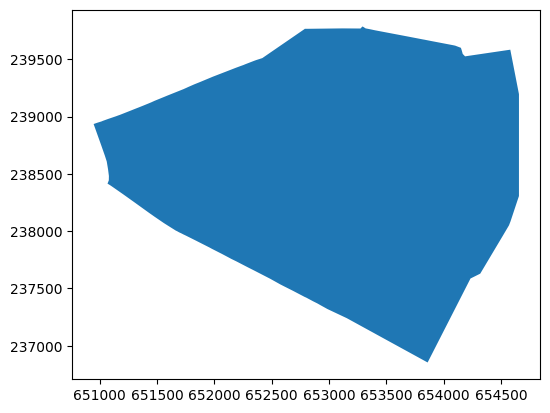

In [3]:
d8 = districts.query("did == '8'").copy().reset_index(drop=True)
d8.plot()

<Axes: >

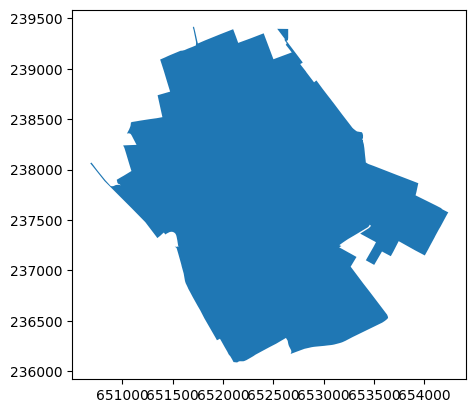

In [4]:
c10 = comm1_5.query("id == 10").copy().reset_index(drop=True)
c10.plot()

In [5]:
sd = d8.symmetric_difference(c10)
rs = d8.intersection(c10)

In [6]:
def build_network(df: gpd.GeoDataFrame) -> nx.Graph:
    locations = {}
    G = nx.DiGraph()
    for row in df.itertuples():
        G.add_node(row.id)
        locations[row.id] = (row.geometry.x, row.geometry.y)
    for u, v in pairwise(df.itertuples()):
        if u.id == v.id:
            continue
        G.add_edge(u.id, v.id)
    return G, locations

In [7]:
area_eov = Polygon(
    [
        Point(650000, 235000),
        Point(650000, 242000),
        Point(656000, 242000),
        Point(656000, 235000),
    ]
)
area = gpd.GeoDataFrame(geometry=[area_eov], crs=23700).to_crs(4326).geometry[0]

In [8]:
ox_bbox = 47.4589579153875, 47.521921622096606, 19.047445636376338, 19.127116119708216
ox_bbox = 19.047445636376338, 47.4589579153875, 19.127116119708216, 47.521921622096606
g = ox.graph_from_bbox(ox_bbox, simplify=False, retain_all=True, network_type="drive")
streets = ox.graph_to_gdfs(g, nodes=False)

In [9]:
hb = gpd.read_file("../data/house_blocks.geojson")
duna = gpd.read_file("../data/barriers/duna.geojson")
land = gpd.GeoSeries(area.difference(duna.union_all()))

In [10]:
comm1_5 = gpd.read_file("../data/louvain_r1.5_merged.geojson")
comm_1 = comm1_5.query("id==1.0").geometry.tolist()[0]
comm_10 = comm1_5.query("id==10.0").geometry.tolist()[0]

In [11]:
c_land = "#eee8aa6f"
c_street = "#d2b48c"
c_ping = "#874312"
c_stop = "#191970"
c_block = "#add8e6"
c_block = "#1e90ff"

expl = gpd.GeoDataFrame(
    {"id": [1, 2, 3]},
    geometry=[Point(652500, 236850), Point(652000, 238600), Point(652700, 240200)],
    crs=23700,
)
g_expl, locations_expl = build_network(expl)

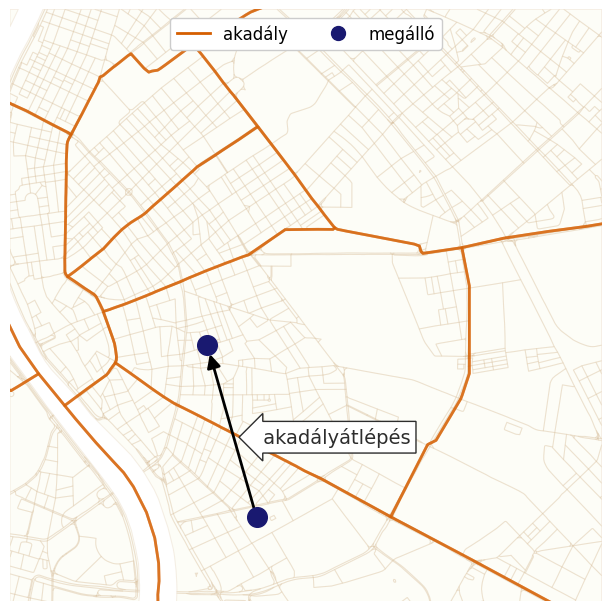

In [86]:
g_expl_s, locations_expl_s = build_network(expl.query("id<3"))

fig3b, ax3b = plt.subplots(figsize=(6, 6), layout="constrained")
land.set_crs(4326).to_crs(23700).plot(color="#eee8aa16", ax=ax3b, zorder=-5)
gpd.clip(hb, area).to_crs(23700).plot(
    ec=c_street + "36", color="none", linewidth=0.75, ax=ax3b, zorder=-4
)
districts.plot(fc="none", ec="#d55e00a0", ax=ax3b, lw=2, zorder=-1)
nx.draw(
    g_expl_s,
    pos=locations_expl,
    ax=ax3b,
    node_color=c_stop,
    edge_color="black",
    node_size=200,
    arrowsize=20,
    width=2,
)

ax3b.text(
    652500,
    237600,
    " akadályátlépés",
    size=14,
    color="#2d2d2d",
    zorder=25,
    bbox=dict(boxstyle="larrow", ec="#2d2d2d", fc="#ffffff"),
)

ax3b.set_xlim((650000, 656000))
ax3b.set_ylim((236000, 242000))

ax3b.margins(0)
ax3b.axis("off")

legend_elements = []
labels = ["akadály", "megálló"]
lcolors = ["#d55e00a0", c_stop]
types = ["Line2D", "Circle"]
for l, c, t in zip(labels, lcolors, types):
    if t == "Patch":
        elem = Patch(fc=c, label=l, alpha=1)
    if t == "Line2D":
        elem = Line2D([0], [0], c=c, label=l, alpha=1, lw=2)
    if t == "Circle":
        elem = Line2D(
            [0],
            [0],
            c=c,
            label=l,
            alpha=1,
            lw=2,
            marker="o",
            linestyle="None",
            markersize=10,
        )
    legend_elements.append(elem)

ax3b.legend(
    handles=legend_elements, ncols=2, loc="upper center", framealpha=1, fontsize=12
)

for i in config["formats"]:
    fig3b.savefig(
        f"../figures/barrier_and_community_crossing_1.{i}",
        dpi=300,
        facecolor="white",  # bbox_inches="tight",
        metadata=config["metadata"],
    )

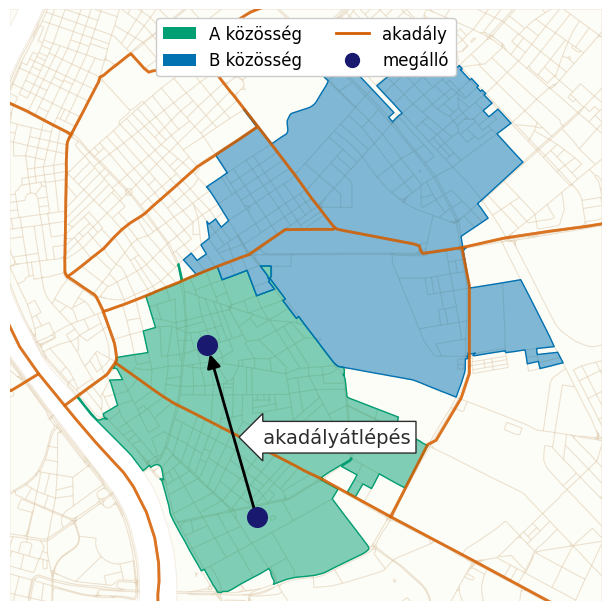

In [87]:
fig3b, ax3b = plt.subplots(figsize=(6, 6), layout="constrained")
land.set_crs(4326).to_crs(23700).plot(color="#eee8aa16", ax=ax3b, zorder=-5)
gpd.clip(hb, area).to_crs(23700).plot(
    ec=c_street + "36", color="none", linewidth=0.75, ax=ax3b, zorder=-4
)
comm1_5.query("id.isin([1.0, 10.0])").plot(
    ax=ax3b, fc=["#009e737f", "#0072b27f"], ec=["#009e73", "#0072b2"], zorder=-2
)
districts.plot(fc="none", ec="#d55e00a0", ax=ax3b, lw=2, zorder=-1)
nx.draw(
    g_expl_s,
    pos=locations_expl_s,
    ax=ax3b,
    node_color=c_stop,
    edge_color="black",
    node_size=200,
    arrowsize=20,
    width=2,
)

ax3b.text(
    652500,
    237600,
    " akadályátlépés",
    size=14,
    color="#2d2d2d",
    zorder=25,
    bbox=dict(boxstyle="larrow", ec="#2d2d2d", fc="#ffffff"),
)

ax3b.set_xlim((650000, 656000))
ax3b.set_ylim((236000, 242000))

ax3b.margins(0)
ax3b.axis("off")

legend_elements = []
labels = ["A közösség", "B közösség", "akadály", "megálló"]
lcolors = ["#009e737f", "#0072b27f", "#d55e00a0", c_stop]
types = ["Patch", "Patch", "Line2D", "Circle"]
for l, c, t in zip(labels, lcolors, types):
    if t == "Patch":
        elem = Patch(fc=c, label=l, alpha=1)
    if t == "Line2D":
        elem = Line2D([0], [0], c=c, label=l, alpha=1, lw=2)
    if t == "Circle":
        elem = Line2D(
            [0],
            [0],
            c=c,
            label=l,
            alpha=1,
            lw=2,
            marker="o",
            linestyle="None",
            markersize=10,
        )
    legend_elements.append(elem)

ax3b.legend(
    handles=legend_elements, ncols=2, loc="upper center", framealpha=1, fontsize=12
)

for i in config["formats"]:
    fig3b.savefig(
        f"../figures/barrier_and_community_crossing_2.{i}",
        dpi=300,
        facecolor="white",  # bbox_inches="tight",
        metadata=config["metadata"],
    )

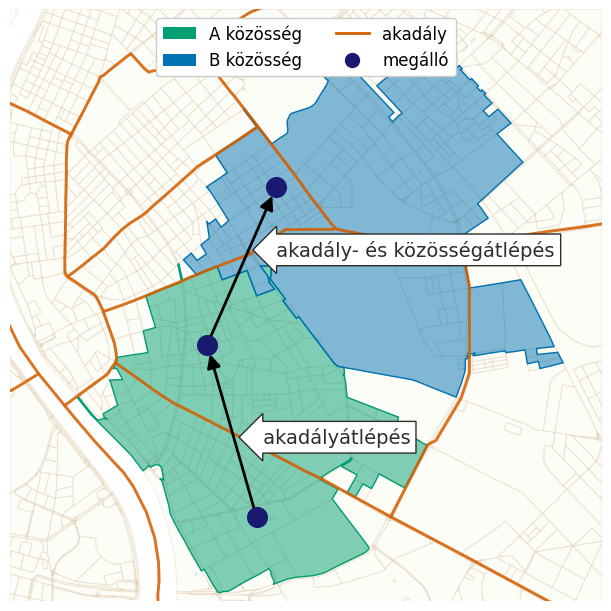

In [88]:
fig3b, ax3b = plt.subplots(figsize=(6, 6), layout="constrained")
land.set_crs(4326).to_crs(23700).plot(color="#eee8aa16", ax=ax3b, zorder=-5)
gpd.clip(hb, area).to_crs(23700).plot(
    ec=c_street + "36", color="none", linewidth=0.75, ax=ax3b, zorder=-4
)
comm1_5.query("id.isin([1.0, 10.0])").plot(
    ax=ax3b, fc=["#009e737f", "#0072b27f"], ec=["#009e73", "#0072b2"], zorder=-2
)
districts.plot(fc="none", ec="#d55e00a0", ax=ax3b, lw=2, zorder=-1)
nx.draw(
    g_expl,
    pos=locations_expl,
    ax=ax3b,
    node_color=c_stop,
    edge_color="black",
    node_size=200,
    arrowsize=20,
    width=2,
)

ax3b.text(
    652500,
    237600,
    " akadályátlépés",
    size=14,
    color="#2d2d2d",
    zorder=25,
    bbox=dict(boxstyle="larrow", ec="#2d2d2d", fc="#ffffff"),
)
ax3b.text(
    652640,
    239500,
    " akadály- és közösségátlépés",
    size=14,
    color="#2d2d2d",
    zorder=25,
    bbox=dict(boxstyle="larrow", ec="#2d2d2d", fc="#ffffff"),
)

ax3b.set_xlim((650000, 656000))
ax3b.set_ylim((236000, 242000))

ax3b.margins(0)
ax3b.axis("off")

legend_elements = []
labels = ["A közösség", "B közösség", "akadály", "megálló"]
lcolors = ["#009e737f", "#0072b27f", "#d55e00a0", c_stop]
types = ["Patch", "Patch", "Line2D", "Circle"]
for l, c, t in zip(labels, lcolors, types):
    if t == "Patch":
        elem = Patch(fc=c, label=l, alpha=1)
    if t == "Line2D":
        elem = Line2D([0], [0], c=c, label=l, alpha=1, lw=2)
    if t == "Circle":
        elem = Line2D(
            [0],
            [0],
            c=c,
            label=l,
            alpha=1,
            lw=2,
            marker="o",
            linestyle="None",
            markersize=10,
        )
    legend_elements.append(elem)

ax3b.legend(
    handles=legend_elements, ncols=2, loc="upper center", framealpha=1, fontsize=12
)

for i in config["formats"]:
    fig3b.savefig(
        f"../figures/barrier_and_community_crossing_3.{i}",
        dpi=300,
        facecolor="white",  # bbox_inches="tight",
        metadata=config["metadata"],
    )

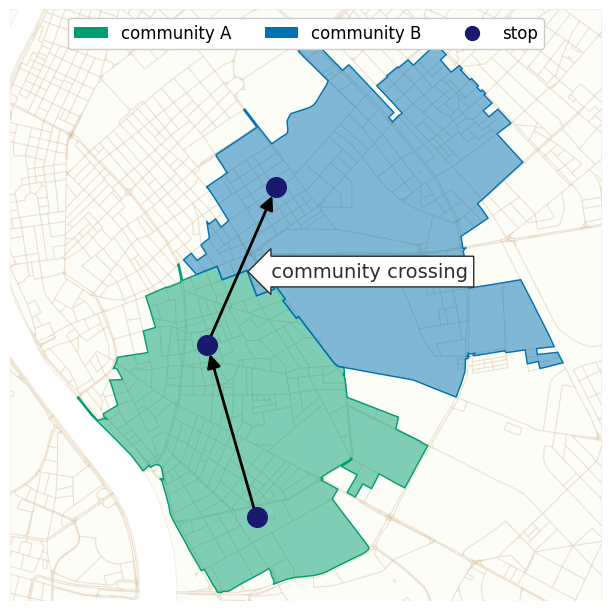

In [ ]:
fig3b, ax3b = plt.subplots(figsize=(6, 6), layout="constrained")
land.set_crs(4326).to_crs(23700).plot(color="#eee8aa16", ax=ax3b, zorder=-5)
gpd.clip(hb, area).to_crs(23700).plot(
    ec=c_street + "36", color="none", linewidth=0.75, ax=ax3b, zorder=-4
)
comm1_5.query("id.isin([1.0, 10.0])").plot(
    ax=ax3b, fc=["#009e737f", "#0072b27f"], ec=["#009e73", "#0072b2"], zorder=-2
)
nx.draw(
    g_expl,
    pos=locations_expl,
    ax=ax3b,
    node_color=c_stop,
    edge_color="black",
    node_size=200,
    arrowsize=20,
    width=2,
)

ax3b.text(
    652585,
    239285,
    " community crossing",
    size=14,
    color="#2d2d2d",
    zorder=25,
    bbox=dict(boxstyle="larrow", ec="#2d2d2d", fc="#ffffff"),
)

ax3b.set_xlim((650000, 656000))
ax3b.set_ylim((236000, 242000))

ax3b.margins(0)
ax3b.axis("off")

legend_elements = []
labels = ["community A", "community B", "stop"]
lcolors = ["#009e737f", "#0072b27f", c_stop]
types = ["Patch", "Patch", "Circle"]
for l, c, t in zip(labels, lcolors, types):
    if t == "Patch":
        elem = Patch(fc=c, label=l, alpha=1)
    if t == "Line2D":
        elem = Line2D([0], [0], c=c, label=l, alpha=1, lw=2)
    if t == "Circle":
        elem = Line2D(
            [0],
            [0],
            c=c,
            label=l,
            alpha=1,
            lw=2,
            marker="o",
            linestyle="None",
            markersize=10,
        )
    legend_elements.append(elem)

ax3b.legend(
    handles=legend_elements, ncols=3, loc="upper center", framealpha=1, fontsize=12
)

for i in config["formats"]:
    fig3b.savefig(
        f"../figures/community_crossing.{i}",
        dpi=300,
        facecolor="white",
        metadata=config["metadata"],
    )